# Spectral, temporal and quality descriptors

`acids_dataset.features` implements a catalog of audio descriptors, written in pure PyTorch : they run on any device,
compute whole batches at once, and give outputs with time last. This notebook shows spectral, temporal and quality
descriptors on synthetic signals whose expected values are known.

Every descriptor is a callable taking audio of shape `(..., channels, samples)`. By default, descriptors are computed on
the mix of channels, such that the channel axis is removed : a mono signal `(1, samples)` gives `(n_frames,)`.

In [3]:
import math
import torch
import matplotlib.pyplot as plt
from acids_dataset import features as F

SR = 22050
torch.manual_seed(0)
t = torch.arange(2 * SR) / SR

def show_spectrogram(ax, x, title=""):
    spec = torch.stft(x, 1024, 256, window=torch.hann_window(1024), return_complex=True).abs()
    ax.imshow(20 * torch.log10(spec + 1e-6), origin="lower", aspect="auto", cmap="magma", vmin=-60,
              extent=[0, x.shape[-1] / SR, 0, SR / 2])
    ax.set_title(title); ax.set_xlabel("time (s)"); ax.set_ylabel("frequency (Hz)")

## Spectral shape

A logarithmic sweep from 100 Hz to 8 kHz : its spectral centroid and rolloff follow the instantaneous frequency.
Frequency descriptors are given in Hz, or with `unit="normalized"` (ratio of Nyquist) or `unit="midi"`.

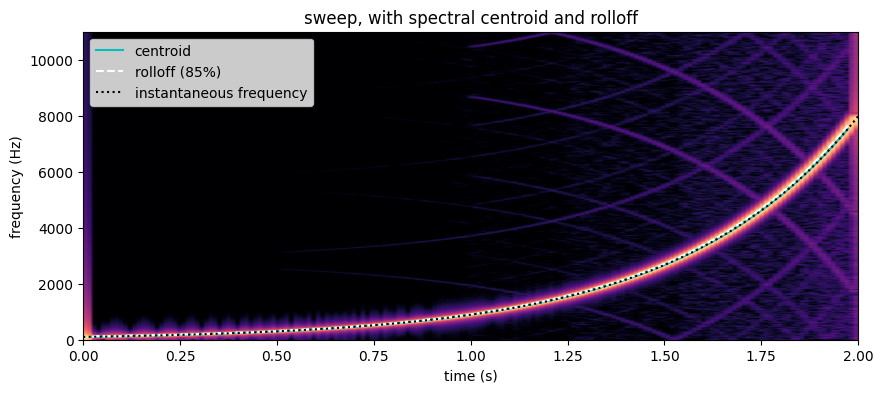

centroid in midi (first / last frames) : tensor([ 45.1187, 115.5802])


In [4]:
f0, f1 = 100., 8000.
phase = 2 * math.pi * f0 * 2 / math.log(f1 / f0) * ((f1 / f0) ** (t / 2) - 1)
sweep = 0.5 * torch.sin(phase)[None]

centroid = F.SpectralCentroid(frame_length=1024, hop_length=256, sr=SR)(sweep)
rolloff = F.SpectralRolloff(frame_length=1024, hop_length=256, sr=SR)(sweep)
frame_times = torch.arange(centroid.shape[-1]) * 256 / SR + 512 / SR

fig, ax = plt.subplots(figsize=(10, 4))
show_spectrogram(ax, sweep[0], "sweep, with spectral centroid and rolloff")
ax.plot(frame_times, centroid, "c", label="centroid")
ax.plot(frame_times, rolloff, "w--", label="rolloff (85%)")
ax.plot(t, f0 * (f1 / f0) ** (t / 2), "k:", label="instantaneous frequency")
ax.legend(loc="upper left"); plt.show()

print("centroid in midi (first / last frames) :", F.SpectralCentroid(unit="midi", sr=SR)(sweep)[[0, -1]])

Flatness separates tones from noise (≈ 0 for tones, ≈ 0.56 for white noise with a hann window), as does the spectral
crest. Spread, skewness and kurtosis describe the shape of the spectrum around its centroid.

In [5]:
signals = {
    "sine 440 Hz": 0.5 * torch.sin(2 * math.pi * 440 * t)[None],
    "harmonic 220 Hz": sum(0.3 / k * torch.sin(2 * math.pi * 220 * k * t) for k in range(1, 15))[None],
    "white noise": 0.2 * torch.randn(1, len(t)),
    "lowpassed noise": torch.nn.functional.conv1d(0.2 * torch.randn(1, 1, len(t)), torch.ones(1, 1, 32) / 8, padding="same")[0],
}
descriptors = {
    "centroid (Hz)": F.SpectralCentroid(sr=SR), "spread (Hz)": F.SpectralSpread(sr=SR),
    "skewness": F.SpectralSkewness(sr=SR), "kurtosis": F.SpectralKurtosis(sr=SR),
    "flatness": F.SpectralFlatness(sr=SR), "crest": F.SpectralCrest(sr=SR), "flux": F.SpectralFlux(sr=SR),
}
print("%-18s" % "" + "".join("%15s" % name for name in descriptors))
for name, x in signals.items():
    print("%-18s" % name + "".join("%15.3f" % d(x).mean() for d in descriptors.values()))

                    centroid (Hz)    spread (Hz)       skewness       kurtosis       flatness          crest           flux
sine 440 Hz               440.000          6.259         17.204      23169.184          0.000        667.929          0.000
harmonic 220 Hz           453.899        473.249          2.934         12.459          0.000        339.219          0.000
white noise              5471.779       3189.132          0.014          1.810          0.570          7.462          0.015
lowpassed noise           415.737        959.914          6.475         54.076          0.020         94.197          0.036


/var/folders/vk/nn1706pd25b57gxz9y3p1wqh0000gn/T/ipykernel_77815/2986111172.py:5: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  "lowpassed noise": torch.nn.functional.conv1d(0.2 * torch.randn(1, 1, len(t)), torch.ones(1, 1, 32) / 8, padding="same")[0],


`SpectralContrast` gives the peak / valley difference (dB) in octave bands : high for harmonic sounds, low for noise.

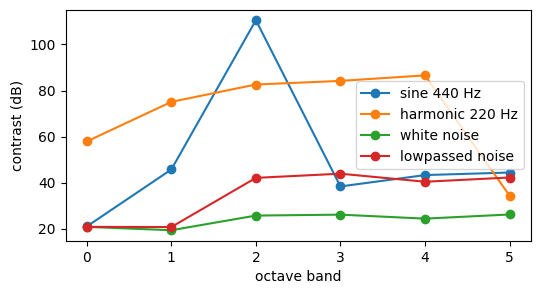

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
for name, x in signals.items():
    ax.plot(F.SpectralContrast(sr=SR)(x).mean(-1), "o-", label=name)       # (n_bands, n_frames) -> (n_bands,)
ax.set_xlabel("octave band"); ax.set_ylabel("contrast (dB)"); ax.legend(); plt.show()

## Temporal descriptors

`RMS` and `ZeroCrossingRate` are per frame ; `AttackTime`, `TemporalCentroid` and `CrestFactor` give one value per
chunk. Here, notes with increasing attack times :

attack 0.005 s -> AttackTime 0.012 s, TemporalCentroid 0.388 s, CrestFactor 13.0 dB
attack 0.050 s -> AttackTime 0.046 s, TemporalCentroid 0.411 s, CrestFactor 12.6 dB
attack 0.200 s -> AttackTime 0.174 s, TemporalCentroid 0.489 s, CrestFactor 11.7 dB
attack 0.500 s -> AttackTime 0.406 s, TemporalCentroid 0.657 s, CrestFactor 10.4 dB


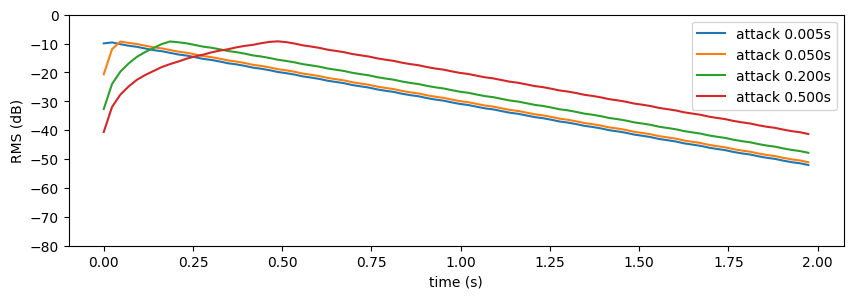

In [7]:
def note(attack, decay=0.4, f=330.):
    env = torch.minimum(t / attack, torch.ones_like(t)) * torch.exp(-torch.clamp(t - attack, min=0) / decay)
    return (0.5 * env * torch.sin(2 * math.pi * f * t))[None]

fig, ax = plt.subplots(figsize=(10, 3))
for attack in [0.005, 0.05, 0.2, 0.5]:
    x = note(attack)
    rms = F.RMS(frame_length=512, sr=SR)(x)
    ax.plot(torch.arange(len(rms)) * 512 / SR, rms, label="attack %.3fs" % attack)
    print("attack %.3f s -> AttackTime %.3f s, TemporalCentroid %.3f s, CrestFactor %.1f dB" % (
        attack, F.AttackTime(sr=SR)(x).item(), F.TemporalCentroid(sr=SR)(x).item(), F.CrestFactor(sr=SR)(x).item()))
ax.set_xlabel("time (s)"); ax.set_ylabel("RMS (dB)"); ax.set_ylim(-80, 0); ax.legend(); plt.show()

With `unit="hz"`, the zero crossing rate is the frequency of a sine with the same rate :

In [8]:
for f in [110, 440, 1760]:
    x = torch.sin(2 * math.pi * f * t)[None]
    print("%5d Hz -> ZCR %.1f Hz" % (f, F.ZeroCrossingRate(unit="hz", sr=SR)(x).mean()))

  110 Hz -> ZCR 110.0 Hz
  440 Hz -> ZCR 439.9 Hz
 1760 Hz -> ZCR 1760.2 Hz


## Quality descriptors

Quality descriptors help to spot faulty files : clipping, DC offset, silences, compressed dynamics.

In [9]:
loud = 2 * torch.sin(2 * math.pi * 440 * t)[None]
quality = {
    "clipped sine": loud.clamp(-1, 1),
    "sine with DC": 0.3 * torch.sin(2 * math.pi * 440 * t)[None] + 0.2,
    "half silent": torch.cat([0.3 * torch.randn(1, SR), torch.zeros(1, SR)], -1),
    "40 dB steps": torch.cat([0.5 * torch.randn(1, SR), 0.005 * torch.randn(1, SR)], -1),
}
for name, x in quality.items():
    print("%-14s clipping %.2f | DC %+.2f | silence %.2f | dynamic range %.1f dB" % (
        name, F.ClippingRatio(sr=SR)(x).item(), F.DCOffset(sr=SR)(x).mean().item(),
        F.SilenceRatio(sr=SR)(x).item(), F.DynamicRange(sr=SR)(x).item()))

clipped sine   clipping 0.67 | DC +0.00 | silence 0.00 | dynamic range 0.0 dB
sine with DC   clipping 0.00 | DC +0.20 | silence 0.00 | dynamic range 0.0 dB
half silent    clipping 0.00 | DC -0.00 | silence 0.48 | dynamic range 0.5 dB
40 dB steps    clipping 0.02 | DC -0.00 | silence 0.00 | dynamic range 40.3 dB


## Channels and batches

Descriptors are computed on the mix of channels by default, or on each channel with `keep_channels=True`. Whole batches
are computed at once with `batch_call` (that gives the same values as computing items one by one).

In [11]:
stereo = torch.cat([signals["sine 440 Hz"], signals["white noise"]])
print("mix          :", F.SpectralFlatness(sr=SR)(stereo).shape)
print("keep_channels:", F.SpectralFlatness(keep_channels=True, sr=SR)(stereo).shape,
      F.SpectralFlatness(keep_channels=True, sr=SR)(stereo).mean(-1))

batch = torch.stack([s for s in signals.values()])           # (4, 1, samples)
centroid = F.SpectralCentroid(sr=SR)
print("batch        :", centroid.batch_call(batch).shape, "supports_batch =", centroid.supports_batch)

mix          : torch.Size([21])
keep_channels: torch.Size([2, 21]) tensor([1.5347e-09, 5.7000e-01])
batch        : torch.Size([4, 21]) supports_batch = True
